# **FV Solver for the coupled Richards' and heat transport equation**
## Parametrization: Capillary Bundle Model

Author: Anne Hermann   \
anne.hermann@uni-tuebingen.de

In [1]:
import sys
sys.path.append('../')
sys.path.append('../../')

import jax.numpy as jnp
from utils.geometry import Geom
import utils.petrophysic as petro
import utils.petrophysics_capillaryBundles as petro_cap
from utils import plotting_utils
import utils.parameter_interpolation as inter
import pickle as pkl


### State file and folder names for interpolation and input data

In [2]:
parametrization = "drying" # permaFoam_omega50, drying, drying_omega10, cap

input_folder = "../../input/era5_land_data/Sweden/"
input_filename = "sim_2312_2405.pkl"

interp_folder = "../../input/interpolation/"
interp_filename = "interpolation_"+parametrization+".pkl"

spinup_folder = "../../output/Simulations_Paper/ERA5_Sweden/spinup/"
spinup_file = "spinup_"+parametrization+".pkl"

save_folder = "../../output/Simulations_Paper/ERA5_Sweden/simulations/"
save_filename = "simulation_"+parametrization+".pkl"

### Mesh Generation

In [3]:
dz = 0.025       # grid spacing [m]
dx = 0.025    # grid spacing [m]
ztot = 1       # height of the cross-sction [m]
xtot = 10   # length of the domain [m]
slope = -0.1   # slope of the domain [-]

geom = Geom(dx, dz, 0, xtot, -ztot, 0, slope)  # geometry object
geom.create_grid()

===============   Creating grid   =============== 
DONE: created grid with  400 x 40 cells.


In [4]:
geom.set_sparsity_pattern_coupled()

===============   Calculating coupled sparsity pattern   =============== 
DONE: calculated coupled sparsity pattern with 316480 nonzero entries.


### Time Discretization

In [5]:
dt = 60*60    # time step [s]
t_end = 180*24*60*60 # end time [s]
maxdt = 60*60       # maximum time step [s]
CN = 1          # Crank-Nicolson weighting parameter implicit/explicit
save_t =24*60*60     # save time [s]
geom.time_discretization(dt, t_end, maxdt, CN,save_t) # time discretization


===============   Creating time discretization   =============== 
DONE: created time discretization.


### Define Soil

In [6]:
# # Sandy soil parameters
soil_type = {1:{}, 2:{}}
soil = jnp.ones((geom.nz,geom.nx))  # soil type array
soil_type[1]["alpha"] = 14.5                        # van Genuchten alpha [1/m]
soil_type[1]["Ksat"] = 8.25e-5                      # saturated hydraulic conductivity [m/s]
soil_type[1]["N"] = 2.68                            # van Genuchten N [-]
soil_type[1]["Theta_r"] = 0.045                     # minimum volumetric water content [-]
soil_type[1]["Theta_s"] = 0.43                      # maximum volumetric water content [-]

# # Loamy soil parameters
indices = jnp.where((geom.Z<=-.25+slope*geom.X) & (geom.Z>=-.5+slope*geom.X))
soil = soil.at[indices].set(2)
soil_type[2]["alpha"] = 1.6
soil_type[2]["Ksat"] = 6.94e-7
soil_type[2]["N"] = 1.37
soil_type[2]["Theta_r"] = 0.034
soil_type[2]["Theta_s"] = 0.46

#geom.set_vanGenuchten_params(Ksat, alpha, N, Theta_r, Theta_s)

### Interpolation of Hydraulic Parameters:
- interpolate $k_{rel}$ w.r.t. $h_c, T$
- interpolate $\theta_l$ w.r.t. $h_c, T$

In [7]:
# discretize S -> hc
Se = jnp.geomspace(1e-7,1-1e-7,int(1e5)) # effective saturation [-]

#   discretize T
T = jnp.append(jnp.append(jnp.arange(-35,-1,1),jnp.arange(-1,0,1e-3)),jnp.array([0.01,20]))#,jnp.arange(0,10,10)) # K

# interpolate krel and theta_l for each soil type
soil_type = inter.interpolate_parameter(Se, T, soil_type, filename=interp_folder+interp_filename, parametrization=parametrization, method='monotonic', extrapolate=True)
del T,Se

# save interpolated soil type parameters
geom.set_soilType(soil, soil_type)

Loaded interpolated soil type from file:  ../../input/interpolation/interpolation_drying.pkl


In [8]:
import matplotlib.pyplot as plt
# Se = jnp.linspace(1e-6,1,10000)
# hc = petro_cap.h_from_S(Se, soil_type[1]["alpha"], soil_type[1]["N"])
# T = jnp.linspace(-50,20,1000)

# X,Y = jnp.meshgrid(hc, T)
# Z = soil_type[1]["theta_l_interp"](X.flatten(), Y.flatten()).reshape(X.shape)

# fig, ax = plt.subplots(figsize=(20,20),subplot_kw={"projection": "3d"})
# ax.view_init(elev=10, azim=-20, roll=0)
# ax.plot_surface(jnp.log10(X),Y,Z, cmap='Blues')

# print(soil_type[1]["k_rel_interp"](10, 1))
# Z = soil_type[1]["k_rel_interp"](X.flatten(), Y.flatten()).reshape(X.shape)
# fig, ax = plt.subplots(figsize=(20,20),subplot_kw={"projection": "3d"})
# ax.view_init(elev=10, azim=-21, roll=0)
# ax.plot_surface(jnp.log10(X),Y,jnp.log10(Z), cmap='Reds')

### Load Spinup Initial State

In [9]:
with open(spinup_folder+spinup_file, 'rb') as pickle_file:
    data = pkl.load(pickle_file)
    X = data['X']
    Z = data['Z']
    theta_l_total = data['theta_l_total']
    theta_i_total = data['theta_i_total']
    T_total = data['T_total']
    h_total = data['h_total']
    h_c_total = data['h_c_total']
    tend_spinup = data['time_array'][-1]

### Top Boundary Condition

Text(0.5, 0, '$t$ $[d]$')

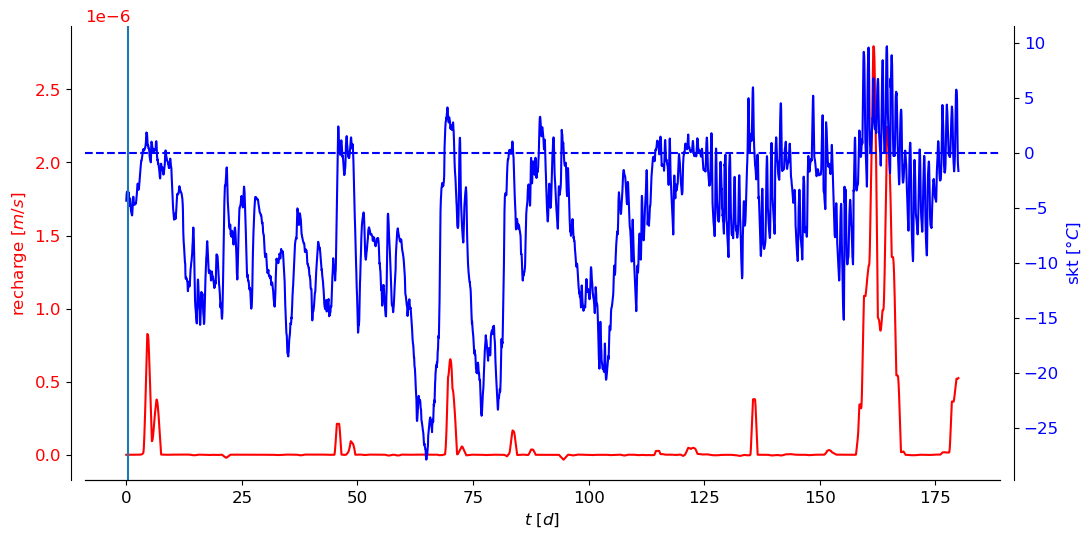

In [10]:
# with open(input_folder + input_filename, "rb") as f:
#     db = pkl.load(f)
#     t_bc = jnp.array(db["time"])
#     idx = t_bc>=tend_spinup
#     q_inf = jnp.array(db["recharge"])[idx]
#     T_surface = jnp.array(db["skt"])[idx]
#     t_bc = t_bc[idx]
#     t_bc = t_bc - t_bc[0]
with open(input_folder + input_filename, "rb") as f:
    db = pkl.load(f)
    t_bc = jnp.array(db["time"])
    q_inf = jnp.convolve(jnp.array(db["recharge"]),jnp.ones(24)/24,mode="same")
    T_surface = jnp.array(db["skt"])
geom.set_surface_bc(t_bc, q_inf, T_surface)

t_plot = jnp.arange(0, t_end,3600)
cm = 1/2.54
fig, ax = plt.subplots(figsize=(30*cm, 15*cm))
ax.plot(t_plot/24/60/60, geom.q_inf_interp(t_plot), label="recharge", color="red")
ax.set_ylabel("recharge $[m/s]$", color="red")
ax.tick_params(axis="y", labelcolor="red")
ax_cp = ax.twinx()
ax_cp.set_ylabel("skt $[°C]$", color="blue")
ax_cp.plot(t_plot/24/60/60, geom.T_surface_interp(t_plot), label="skt", color="blue")
ax_cp.tick_params(axis="y", labelcolor="blue")
ax_cp.axhline(0, color="blue", linestyle="--")
ax_cp.axvline(0.46)
ax.spines["top"].set_visible(False)
ax_cp.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax_cp.spines["left"].set_visible(False)
ax.spines['left'].set_position(('outward', 10))
ax_cp.spines['right'].set_position(('outward', 10))

ax.set_xlabel("$t$ $[d]$")

### Initial Condition

In [11]:
Theta_l = theta_l_total[-1]
Theta_i = theta_i_total[-1]
h_c = h_c_total[-1]
htot = h_total[-1]
T_init = T_total[-1]
geom.set_initial_conditions(htot, h_c, Theta_l, Theta_i, T_init)

===============   Setting initial conditions   =============== 
DONE: set initial conditions.


### Plot Inital $\theta_l$ and $k_{rel}$

(<Figure size 1181.1x787.402 with 2 Axes>,
 <Axes: title={'center': 'Initial $\\theta_i$'}, xlabel='x [m]', ylabel='z [m]'>)

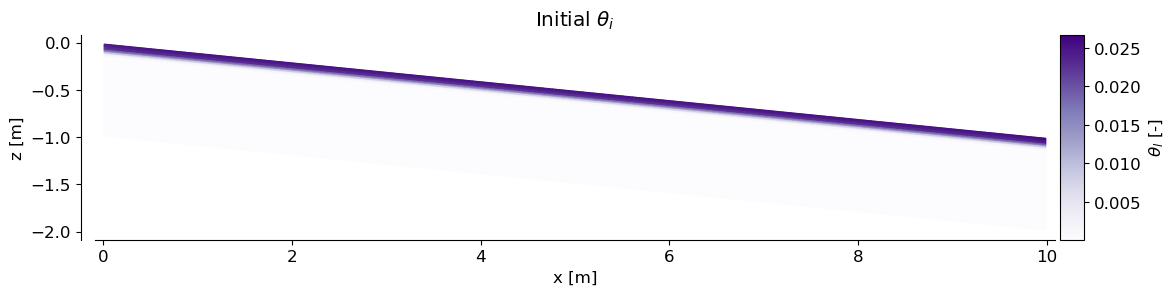

In [12]:
theta_l = jnp.where(geom.soil==1, geom.soil_type[1]["theta_l_interp"](h_c.flatten(), T_init.flatten()).reshape(h_c.shape), geom.soil_type[2]["theta_l_interp"](h_c.flatten(), T_init.flatten()).reshape(h_c.shape))
plotting_utils.plot_cellValues(geom.X,geom.Z, Theta_i, colormap="Purples", title=r"Initial $\theta_i$", colorbar_label=r'$\theta_l$ [-]')

(<Figure size 1181.1x787.402 with 2 Axes>,
 <Axes: title={'center': '$T$ [°C]'}, xlabel='x [m]', ylabel='z [m]'>)

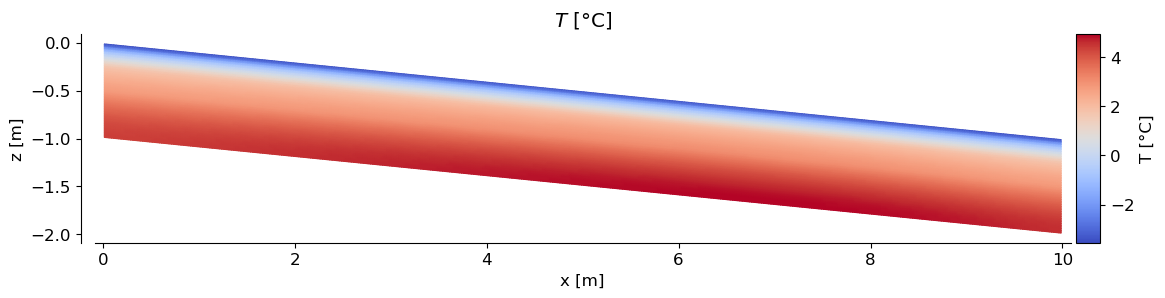

In [13]:
krel = jnp.where(geom.soil==1, geom.soil_type[1]["k_rel_interp"](h_c.flatten(), T_init.flatten()).reshape(h_c.shape), geom.soil_type[2]["k_rel_interp"](h_c.flatten(), T_init.flatten()).reshape(h_c.shape))
plotting_utils.plot_cellValues(geom.X,geom.Z, T_init, colormap="coolwarm", title=r"$T$ [°C]", colorbar_label=r'T [°C]')

### Set Initial Condition

In [14]:
geom.set_initial_conditions(htot, h_c, theta_l, 0*theta_l, T_init)

===============   Setting initial conditions   =============== 
DONE: set initial conditions.


### Thermal Parameters

In [15]:
rho_l = 1000
rho_i = 917
rho_s = 2650
rho_a = 1200

c_s = 800
c_l = 4180
c_i = 2100
c_a = 1000

H_f = 3.34e5
geom.set_thermal_params(rho_l, rho_i, rho_s, rho_a, c_l, c_i, c_s, c_a, H_f)

### Numerical Parameters

In [16]:
restol_rich=1e-4;      # accepted residual in Newton step
restol_T=1e-4
maxiter=10;      # maxmum number of iterations in Newton step
miniter=5;        # minimum number of iterations in Newton step

geom.set_solver_params(restol_rich,restol_T, maxiter, miniter,solver='newton')

===============   Setting Newton-Raphson parameters   =============== 
Restol: (0.0001, 0.0001)
Max Iterations: 10
Min Iterations: 5
DONE: set Newton-Raphson parameters.


In [17]:
[h_total, h_c_total, theta_l_total,theta_i_total, T_total,q_runoff, qx_array,qz_array,qx_centered_array,qz_centered_array, time_array, iter_total, normres_total]=geom.simulate_cap_bundle()

Starting simulation ...
Time 0.04 d, dt=3.60e+03, NR iterations=4, ||res_rich||_inf=2.427e-16, ||res_T||_inf=2.918e-03
Time 0.08 d, dt=3.60e+03, NR iterations=4, ||res_rich||_inf=2.107e-16, ||res_T||_inf=5.458e-06
Time 0.12 d, dt=3.60e+03, NR iterations=3, ||res_rich||_inf=1.252e-12, ||res_T||_inf=1.971e-01
Time 0.17 d, dt=3.60e+03, NR iterations=3, ||res_rich||_inf=4.406e-13, ||res_T||_inf=1.522e-01
Time 0.21 d, dt=3.60e+03, NR iterations=3, ||res_rich||_inf=1.122e-12, ||res_T||_inf=1.210e-01
Time 0.25 d, dt=3.60e+03, NR iterations=3, ||res_rich||_inf=1.403e-12, ||res_T||_inf=1.040e-01
Time 0.29 d, dt=3.60e+03, NR iterations=3, ||res_rich||_inf=6.425e-13, ||res_T||_inf=3.732e-02
Time 0.33 d, dt=3.60e+03, NR iterations=3, ||res_rich||_inf=4.374e-13, ||res_T||_inf=2.090e-02
Time 0.38 d, dt=3.60e+03, NR iterations=3, ||res_rich||_inf=6.638e-14, ||res_T||_inf=6.959e-03
Time 0.42 d, dt=3.60e+03, NR iterations=3, ||res_rich||_inf=4.948e-14, ||res_T||_inf=3.774e-03
Time 0.46 d, dt=3.60e+03, 

[-0.05366776 -0.05375257 -0.05394052 -0.05427009 -0.05476852 -0.05543483
 -0.05625071 -0.05719365 -0.05824291 -0.05938132 -0.06059563 -0.06187647
 -0.06321789 -0.06461684 -0.06607256 -0.06758609 -0.06915983 -0.07079727
 -0.07250269 -0.07428104 -0.07556496 -0.07653516 -0.07777548 -0.07929307
 -0.08109102 -0.08316493 -0.08549846 -0.08805891 -0.09079403 -0.09363278
 -0.09839094 -0.10499055 -0.11151005 -0.11787774 -0.12405238 -0.13002602
 -0.13582522 -0.14150915 -0.14716208 -0.15287786]


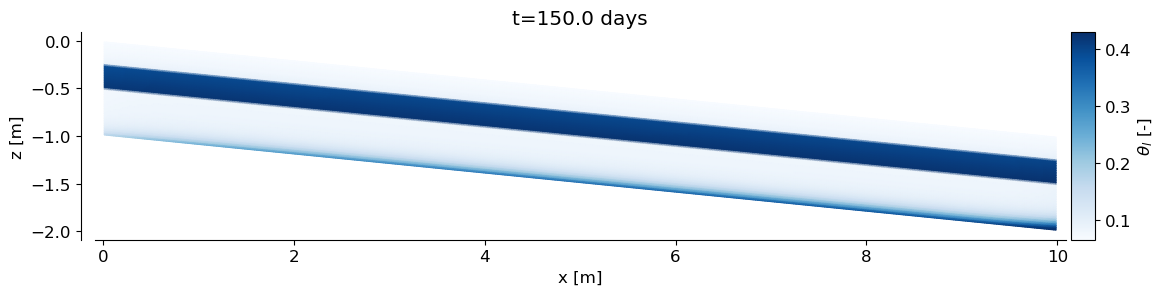

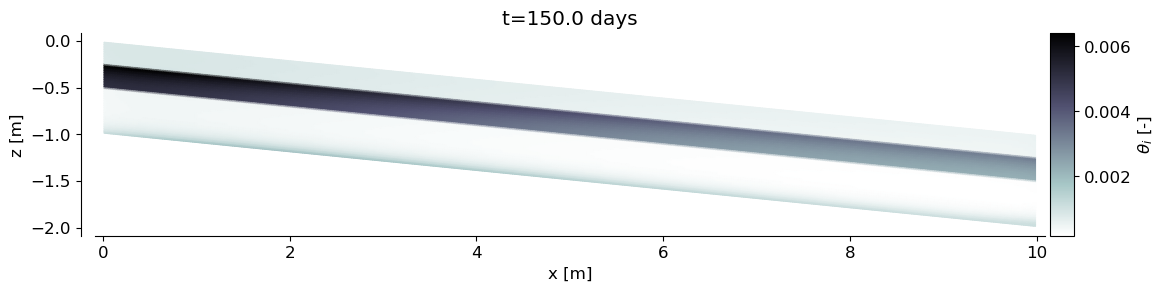

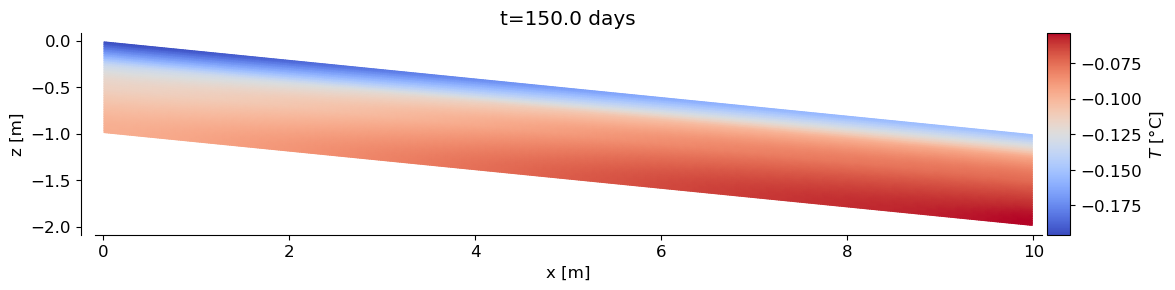

In [23]:
index = 150  # final time step

# plotting_utils.plot_lineProfile(geom, Se, krel, x_position=60, xlabel1=r"$S_e$ [m]", xlabel2=r"$k_{rl}$ [-]")

plotting_utils.plot_cellValues(geom.X,geom.Z, theta_l_total[index], colormap="Blues", title=f"t={jnp.round(time_array[index]/60/60/24)} days", colorbar_label=r'$\theta_l$ [-]')
plotting_utils.plot_cellValues(geom.X,geom.Z, theta_i_total[index], colormap="bone_r", title=f"t={jnp.round(time_array[index]/60/60/24)} days", colorbar_label=r'$\theta_i$ [-]')
plotting_utils.plot_cellValues(geom.X,geom.Z, T_total[index], colormap="coolwarm", title=f"t={jnp.round(time_array[index]/60/60/24)} days", colorbar_label=r'$T$ [°C]')
print(T_total[index][:,-3])

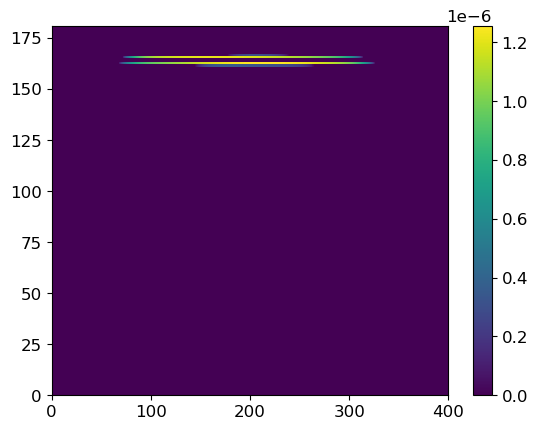

In [19]:
plt.pcolormesh(q_runoff)
plt.colorbar()

In [20]:
# Save simulation output in pickle file
db = {"X": geom.X, "Z":geom.Z,"X_plot":geom.X_plot, "Z_plot":geom.Z_plot, "q_runoff":q_runoff,
      "q_inf_interp":geom.q_inf_interp,"T_surface_interp": geom.T_surface_interp,
      "h_total": h_total, "h_c_total": h_c_total,"theta_l_total":theta_l_total, "theta_i_total":theta_i_total,"T_total": T_total, 
      "qx_array":qx_array,"qz_array":qz_array,"qx_centered_array":qx_centered_array,"qz_centered_array":qz_centered_array,
      "time_array": time_array, "iter_total": iter_total, "normres_total": normres_total}
with open(save_folder + save_filename, 'wb') as pickle_file:
    pkl.dump(db, pickle_file)